In [ ]:
!git clone https://github.com/sulysoto/Codigos-de-R.git

Cloning into 'Codigos-de-R'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (68/68), done.
remote: Total 71 (delta 19), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (71/71), 5.16 MiB | 9.05 MiB/s, done.
Resolving deltas: 100% (19/19), done.


In [ ]:
import glob
l_db = glob.glob("./Codigos-de-R/DBs/examples-of-electromyograms-1.0.0/**.txt", recursive=True)
l_db

['./Codigos-de-R/DBs/examples-of-electromyograms-1.0.0/emg_healthy.txt',
 './Codigos-de-R/DBs/examples-of-electromyograms-1.0.0/SHA256SUMS.txt',
 './Codigos-de-R/DBs/examples-of-electromyograms-1.0.0/emg_neuropathy.txt',
 './Codigos-de-R/DBs/examples-of-electromyograms-1.0.0/emg_myopathy.txt']

In [ ]:
emg_heal = l_db[0]
emg_neu =l_db[2]
emg_myo = l_db[3]

# EMG

https://physionet.org/content/emgdb/1.0.0/

In [ ]:
import pandas as pd
import numpy as np

sig_emg_heal = np.fromfile(emg_heal, dtype=np.float32)
sig_emg_neu = np.fromfile(emg_neu, dtype=np.float32)
sig_emg_myo = np.fromfile(emg_myo, dtype=np.float32)

In [ ]:
fs = 5e3
ts = 1/fs
n = np.arange(len(sig_emg_myo ))
t = n*ts

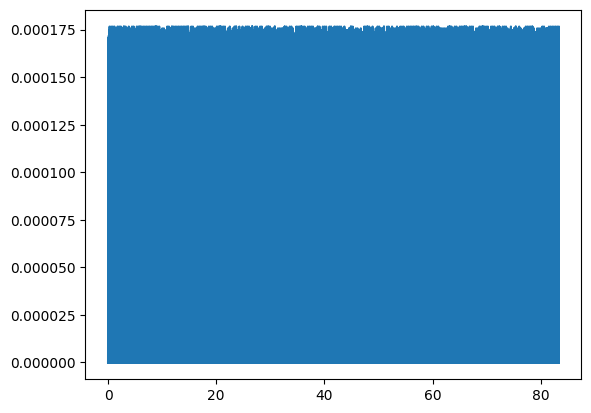

In [ ]:
import matplotlib.pyplot as plt

plt.plot(t, sig_emg_myo )
#plt.plot(sig_emg_neu)
#plt.plot(sig_emg_myo)

#plt.xlim(0, 100000)
#plt.show()

In [ ]:
!pip install wfdb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 74.6 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.3 which is incompatible.


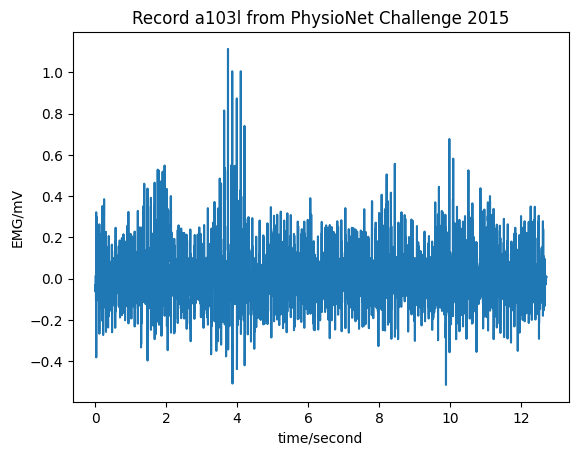

In [ ]:
import wfdb

wfdb_emg_healthy = wfdb.rdrecord('/content/Codigos-de-R/DBs/examples-of-electromyograms-1.0.0/emg_healthy')
wfdb.plot_wfdb(record=wfdb_emg_healthy, title='Record a103l from PhysioNet Challenge 2015')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

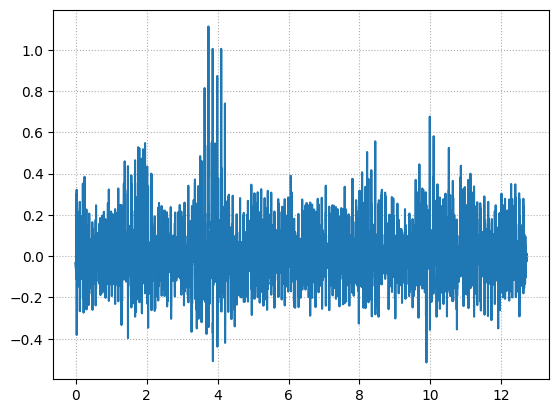

In [ ]:
fs = wfdb_emg_healthy.fs
ts = 1/fs

s_health = wfdb_emg_healthy.p_signal.flatten()
s_health

n = np.arange(len(s_health))
t = n*ts

plt.plot(t, s_health)
plt.grid(ls=":")

In [ ]:
fs

4000

In [ ]:
from scipy import signal

b,a = signal.butter(4, Wn=[10,450], btype="bandpass", output="ba", fs=fs)

In [ ]:
s1 = signal.lfilter(b, a, s_health)

s1

array([-0.00022182, -0.00160242, -0.00552544, ...,  0.00771666,
        0.00612741,  0.00453332])

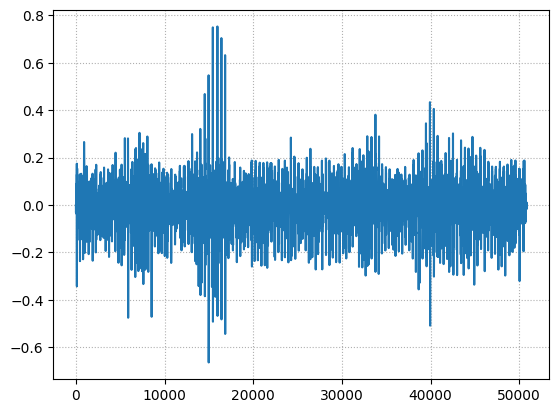

In [ ]:
plt.plot(s1)
plt.grid(ls=":")

(-1.0, 2.0)

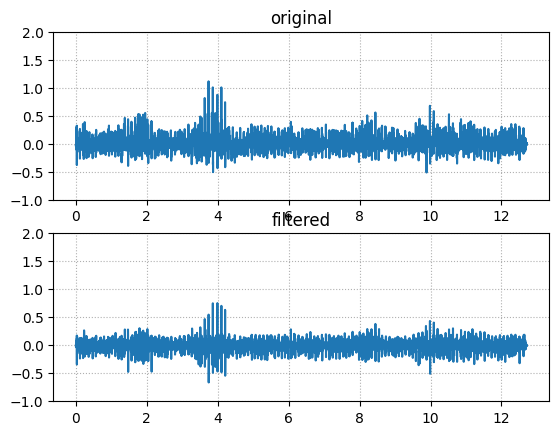

In [ ]:
plt.subplot(2,1,1)
plt.plot(t, s_health)
plt.grid(ls=":")
plt.title("original")
plt.ylim(-1,2)

plt.subplot(2,1,2)
plt.plot(t, s1)
plt.grid(ls=":")
plt.title("filtered")
plt.ylim(-1,2)

In [ ]:
ts

0.00025

In [ ]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

# 1. Crear una señal de ejemplo (10 muestras)
#señal = np.arange(10) # [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# 2. Definir parámetros
tamaño_ventana = 4000
overlap = 0.5
salto = int(tamaño_ventana * (1 - overlap)) # Para 50%, salto = 2

# 3. Crear TODAS las ventanas posibles (avanzando de 1 en 1)
todas_las_ventanas = sliding_window_view(s1, window_shape=tamaño_ventana)

# 4. Filtrar aplicando el salto (hop_length) para obtener el 50% de overlap
ventanas_50_overlap = todas_las_ventanas[::salto]

ventanas_50_overlap

array([[-0.00022182, -0.00160242, -0.00552544, ...,  0.06427622,
         0.05803586,  0.03006286],
       [ 0.02304588,  0.0217551 ,  0.01958365, ...,  0.00739788,
         0.0111924 ,  0.01499296],
       [-0.0094433 , -0.04976731, -0.08163809, ..., -0.01428967,
        -0.02242918, -0.03295665],
       ...,
       [ 0.01058666,  0.00568722,  0.00027367, ..., -0.00200013,
        -0.00297027, -0.00392526],
       [ 0.08351441,  0.08405213,  0.0833367 , ..., -0.01459053,
        -0.01130753, -0.00989413],
       [-0.00459969, -0.00488601, -0.00479748, ..., -0.00027191,
        -0.00033272, -0.00177454]])

In [ ]:
ventanas_50_overlap.shape

(24, 4000)

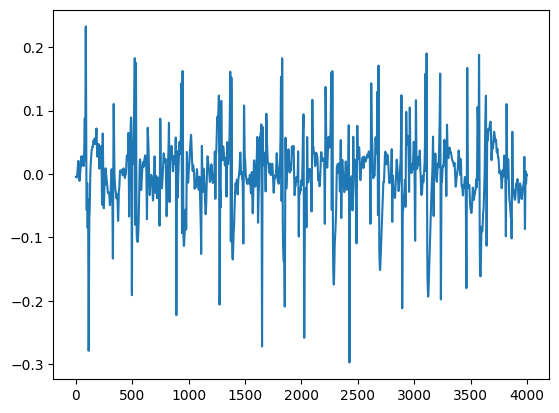

In [ ]:
plt.plot(ventanas_50_overlap[23,:])

In [ ]:
from scipy.stats import kurtosis, skew

In [ ]:
def VAR(s):
    return np.var(s)

def RMS(s):
    return np.sqrt(np.mean(s**2))

def KURTOSIS(s):
    return kurtosis(s)

def SKEW(s):
    return skew(s)

In [ ]:
import pandas as pd

df = pd.DataFrame(ventanas_50_overlap)
df

,0,1,2,3,4,5,6,7,8,9,...,3990,3991,3992,3993,3994,3995,3996,3997,3998,3999
0,-0.000222,-0.001602,-0.005525,-0.012351,-0.020505,-0.027407,-0.031170,-0.031488,-0.029363,-0.026307,...,-0.065289,-0.115636,-0.130026,-0.107062,-0.057970,-0.001530,0.043390,0.064276,0.058036,0.030063
1,0.023046,0.021755,0.019584,0.016572,0.011795,0.004638,-0.004547,-0.014617,-0.024114,-0.031674,...,0.009456,0.008008,0.006541,0.004998,0.003705,0.003371,0.004591,0.007398,0.011192,0.014993
2,-0.009443,-0.049767,-0.081638,-0.097195,-0.094040,-0.080227,-0.069113,-0.068751,-0.078322,-0.091809,...,-0.020593,-0.018676,-0.015760,-0.012322,-0.009305,-0.007951,-0.009409,-0.014290,-0.022429,-0.032957
3,0.017781,0.018799,0.017748,0.014874,0.011709,0.011695,0.017117,0.024980,0.029139,0.026031,...,0.010565,0.010715,0.011113,0.011813,0.012766,0.013829,0.014809,0.015524,0.015861,0.015723
4,-0.044536,-0.055595,-0.064403,-0.069214,-0.068686,-0.062406,-0.050343,-0.031836,-0.007982,0.015243,...,0.020399,0.021603,0.023640,0.026737,0.030598,0.034466,0.037360,0.038412,0.037219,0.033999
5,0.014881,0.013012,0.009911,0.005663,0.000729,-0.004133,-0.008217,-0.011125,-0.012083,-0.009228,...,0.001441,0.003128,0.004060,0.004018,0.003033,0.001279,-0.000983,-0.003406,-0.005575,-0.007101
6,0.029501,0.024681,0.020276,0.016603,0.013682,0.011423,0.009686,0.008268,0.006894,0.005269,...,-0.104445,-0.085838,-0.069399,-0.054282,-0.039715,-0.025198,-0.010640,0.003421,0.015603,0.023919
7,-0.007813,-0.007847,-0.007422,-0.006560,-0.005034,-0.002554,0.000940,0.005130,0.009444,0.013283,...,0.033122,0.033899,0.034493,0.034760,0.034603,0.033954,0.032765,0.031066,0.029027,0.026964
8,0.026522,0.022798,0.014603,0.006702,0.005945,0.018733,0.047451,0.088398,0.132515,0.168957,...,-0.016463,-0.020123,-0.022396,-0.023125,-0.022382,-0.020290,-0.017061,-0.013119,-0.009071,-0.005553
9,0.025198,0.023865,0.022817,0.021758,0.020468,0.018955,0.017469,0.016358,0.015827,0.015770,...,-0.108392,-0.102059,-0.095459,-0.089523,-0.084732,-0.081105,-0.078338,-0.075885,-0.072897,-0.068398


In [ ]:
df.var(axis=1)

0     0.003190
1     0.002873
2     0.004517
3     0.004692
4     0.002913
5     0.002848
6     0.010855
7     0.013930
8     0.006261
9     0.002845
10    0.002917
11    0.002440
12    0.002534
13    0.002707
14    0.002684
15    0.004072
16    0.004055
17    0.002286
18    0.004018
19    0.005512
20    0.004797
21    0.004326
22    0.003323
23    0.003054
dtype: float64

In [ ]:
# Varianza
varianza = df.var(axis=1)

# RMS (Raíz cuadrada de la media de los valores al cuadrado)
rms = np.sqrt((df**2).mean(axis=1))

# Kurtosis (Curtosis)
kurtosis = df.kurtosis(axis=1)

# Skewness (Asimetría)
skewness = df.skew(axis=1)

# 3. Unir todo en un nuevo DataFrame
df_caracteristicas = pd.DataFrame({
    'Varianza': varianza,
    'RMS': rms,
    'Kurtosis': kurtosis,
    'Skewness': skewness
})

In [ ]:
df_caracteristicas

,Varianza,RMS,Kurtosis,Skewness
0,0.003190,0.056471,3.957392,-0.283973
1,0.002873,0.053589,8.369636,-0.933832
2,0.004517,0.067200,6.094480,-0.903751
3,0.004692,0.068487,5.774030,-0.980192
4,0.002913,0.053964,9.234788,-1.311003
5,0.002848,0.053360,5.822591,-0.465188
6,0.010855,0.104177,12.601785,-0.676810
7,0.013930,0.118015,9.951728,-0.439587
8,0.006261,0.079117,16.050939,0.015548
9,0.002845,0.053347,3.460477,-0.699442


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_reducido = pca.fit_transform(df_caracteristicas)

In [ ]:
X_reducido

array([[-2.28118385,  0.3091556 ],
       [ 2.12803872, -0.36075491],
       [-0.14690086, -0.32026989],
       [-0.46768828, -0.39524619],
       [ 2.99147019, -0.74184783],
       [-0.4168453 ,  0.11945336],
       [ 6.36145262, -0.12272706],
       [ 3.7125572 ,  0.12660056],
       [ 9.81360593,  0.55381926],
       [-2.77998366, -0.1040614 ],
       [-2.48097384, -0.04029618],
       [-0.86295571,  0.17047543],
       [-0.62779173,  0.05296471],
       [-1.67892022, -0.08796822],
       [-2.1023888 ,  0.18942749],
       [-1.94196172,  0.27918514],
       [-1.88006248,  0.25925162],
       [-2.04822893,  0.18162615],
       [ 3.1747504 , -0.08349587],
       [-0.11328662, -0.02705387],
       [-1.90816302, -0.09867834],
       [-1.90549354,  0.05419394],
       [-1.65565876,  0.20746615],
       [-2.88338773, -0.12121964]])

(-10.0, 10.0)

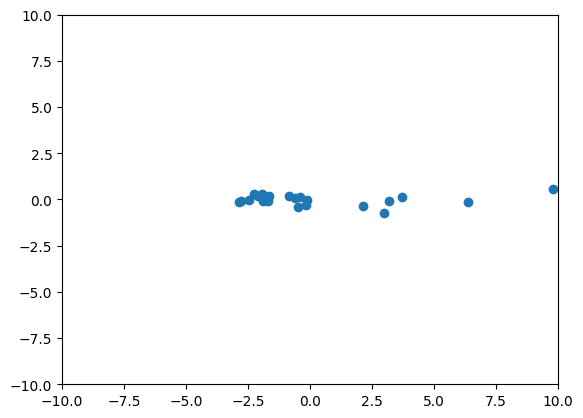

In [ ]:
plt.scatter(X_reducido[:,0], X_reducido[:,1])
plt.xlim(-10,10)
plt.ylim(-10,10)

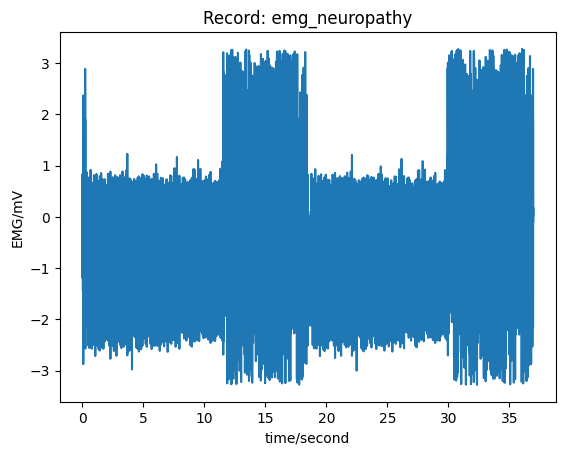

In [ ]:
wfdb_emg_neu = wfdb.rdrecord('/content/Codigos-de-R/DBs/examples-of-electromyograms-1.0.0/emg_neuropathy')
wfdb.plot_wfdb(record=wfdb_emg_neu)

In [ ]:
s_neu = wfdb_emg_neu.p_signal.flatten()

In [ ]:
s2 = signal.lfilter(b, a, s_neu)

In [ ]:
todas_las_ventanas = sliding_window_view(s2, window_shape=tamaño_ventana)

# 4. Filtrar aplicando el salto (hop_length) para obtener el 50% de overlap
s2_bank = todas_las_ventanas[::salto]

s2_bank

array([[ 0.00059952,  0.00421166,  0.0140786 , ...,  0.17460297,
         0.16502015,  0.09474115],
       [ 0.009717  ,  0.01679979,  0.02641984, ..., -0.02509894,
        -0.02900913, -0.02969032],
       [-0.03423359, -0.18833325, -0.31766939, ..., -0.05965926,
        -0.06063856, -0.05895105],
       ...,
       [ 0.06308271,  0.08340058,  0.10306021, ...,  0.06119935,
         0.05999242,  0.05726765],
       [-0.00977348, -0.03980262, -0.06692071, ..., -0.33649141,
        -0.00840203,  0.25125496],
       [ 0.05124331,  0.03905291,  0.01617818, ...,  0.16476051,
         0.11731538,  0.07644273]])

In [ ]:
df2 = pd.DataFrame(s2_bank)
df2

,0,1,2,3,4,5,6,7,8,9,...,3990,3991,3992,3993,3994,3995,3996,3997,3998,3999
0,0.000600,0.004212,0.014079,0.030522,0.049385,0.064742,0.072429,0.071866,0.066060,0.060490,...,0.085330,0.083315,0.083181,0.087098,0.097724,0.118346,0.148882,0.174603,0.165020,0.094741
1,0.009717,0.016800,0.026420,0.039662,0.053754,0.063962,0.067616,0.065154,0.058856,0.050969,...,0.006714,0.005984,0.004387,0.001187,-0.004067,-0.011066,-0.018630,-0.025099,-0.029009,-0.029690
2,-0.034234,-0.188333,-0.317669,-0.379946,-0.357982,-0.266311,-0.143311,-0.028795,0.055206,0.107170,...,0.001513,-0.013400,-0.025267,-0.035153,-0.043595,-0.050666,-0.056165,-0.059659,-0.060639,-0.058951
3,-0.027451,-0.023350,-0.018766,-0.014987,-0.012937,-0.012213,-0.009991,-0.003913,0.003305,0.005885,...,0.787425,0.662197,0.484981,0.322630,0.209566,0.149231,0.126329,0.120478,0.115852,0.104988
4,-0.055060,-0.049801,-0.043954,-0.038051,-0.032514,-0.027929,-0.025002,-0.023553,-0.021520,-0.017053,...,0.020101,0.039391,0.068832,0.107177,0.152207,0.201969,0.255228,0.310646,0.360974,0.383010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,0.044815,0.106725,0.165577,0.220519,0.270758,0.315244,0.348722,0.353238,0.294793,0.131110,...,0.052870,0.041048,0.025905,0.010875,0.000038,-0.003713,0.000157,0.010435,0.025367,0.043350
68,0.123186,0.102894,0.021457,-0.071753,-0.127836,-0.122817,-0.063799,0.021648,0.102233,0.156187,...,0.257702,0.190797,0.120810,0.072285,0.050920,0.048863,0.053074,0.052333,0.040896,0.018859
69,0.063083,0.083401,0.103060,0.120630,0.134491,0.142943,0.144644,0.139241,0.127645,0.111864,...,0.044277,0.050986,0.056094,0.059395,0.061109,0.061732,0.061708,0.061199,0.059992,0.057268
70,-0.009773,-0.039803,-0.066921,-0.088617,-0.104221,-0.114594,-0.121661,-0.127843,-0.135154,-0.144045,...,-0.063704,-0.333842,-0.630748,-0.867679,-0.966194,-0.890101,-0.658594,-0.336491,-0.008402,0.251255


In [ ]:
# Varianza
varianza = df2.var(axis=1)

# RMS (Raíz cuadrada de la media de los valores al cuadrado)
rms = np.sqrt((df2**2).mean(axis=1))

# Kurtosis (Curtosis)
kurtosis = df2.kurtosis(axis=1)

# Skewness (Asimetría)
skewness = df2.skew(axis=1)

# 3. Unir todo en un nuevo DataFrame
df_caracteristicas2 = pd.DataFrame({
    'Varianza': varianza,
    'RMS': rms,
    'Kurtosis': kurtosis,
    'Skewness': skewness
})

In [ ]:
pca = PCA(n_components=2)
X_reducido2 = pca.fit_transform(df_caracteristicas2)

(-20.0, 20.0)

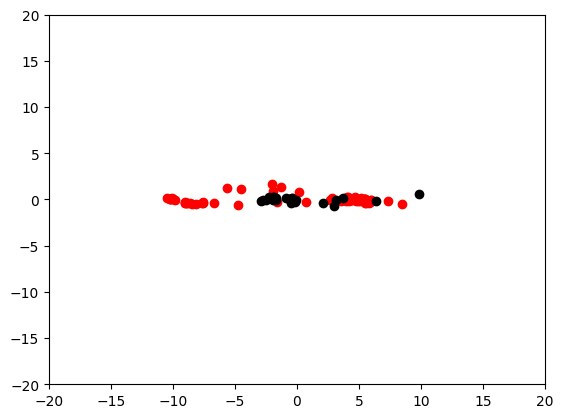

In [ ]:
plt.scatter(X_reducido2[:,0], X_reducido2[:,1], c="red")
plt.scatter(X_reducido[:,0], X_reducido[:,1], c="black")
plt.xlim(-20,20)
plt.ylim(-20,20)

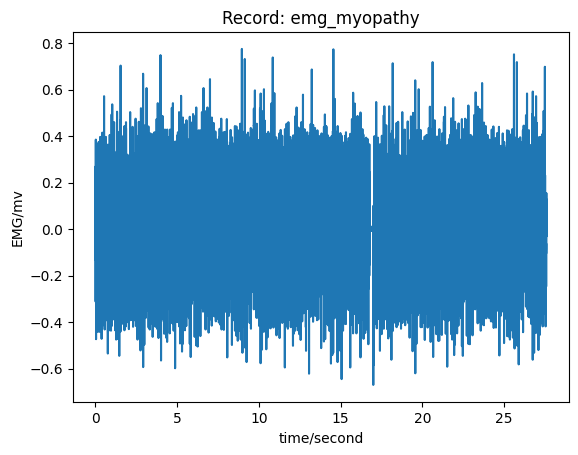

In [ ]:
wfdb_emg_myopathy = wfdb.rdrecord('/content/Codigos-de-R/DBs/examples-of-electromyograms-1.0.0/emg_myopathy')
wfdb.plot_wfdb(record=wfdb_emg_myopathy)